In [ ]:
#LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import random
import shutil
import subprocess
import warnings
from pathlib import Path
import librosa, sounddevice as sd
import joblib
from collections import Counter

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV
# Portable folder configuration for GitHub readers.
# Raw recordings must be obtained separately and are NOT stored in this repository.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = Path(os.environ.get("VOICE_PATHOLOGY_DATA_DIR", PROJECT_ROOT / "data")).expanduser().resolve()
OUTPUT_ROOT = Path(os.environ.get("VOICE_PATHOLOGY_OUTPUT_DIR", PROJECT_ROOT / "outputs")).expanduser().resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


First of all, let's see how many files per class, modality, vowel, and condition there are:

In [ ]:

DATASET_DIR = str(DATA_ROOT / "Speech_pathologies_dataset")

CLASSES = ["Healthy", "Laryngitis", "Hyperfunctional_Dysphonia", "Recurrent_Laryngeal_Nerve_Paralysis"]

#File extensions to consider (EGG and NSP)
VALID_ENDINGS = (".egg", ".nsp")

#Vowels and condition tags to detect in filenames
VOWEL_PATTERNS = ("-a", "-i", "-u")
CONDITION_TAGS = ("_h", "_n", "_l", "_lhl") 


def is_valid_audio(filename: str): 
    #Return True if filename has an accepted extension (.egg or .nsp).
    return filename.lower().endswith(VALID_ENDINGS)


def file_type(filename: str): 
    #Identify if a file is EGG or NSP by its name. Return 'EGG', 'NSP', or None.
    name = filename.lower()
    if "egg" in name:
        return "EGG"
    if "nsp" in name:
        return "NSP"
    return None #None, to avoid missclassifications if the file is not EGG or NSP


def vowel_from_name(filename: str): 
    #Extract the vowel letter 'a'/'i'/'u' from patterns like '-a', '-i', '-u'.
    name = filename.lower()
    for vowel_pattern in VOWEL_PATTERNS:
        if vowel_pattern in name:
            return vowel_pattern[-1]  
    return None


def condition_from_name(filename: str): 
    #Extract the condition tag from the filename, or 'unknown' if not found.
    name = filename.lower()
    for condition_tag in CONDITION_TAGS:
        if condition_tag in name:
            return condition_tag
    return "unknown"


def patient_id_from_name(filename: str): 
    #Extract the patient ID (numbers before the first '-')
    base_name = os.path.basename(filename)
    patient_id = base_name.split("-")[0]
    return patient_id if patient_id.isdigit() else "unknown"


def main():
    file_counts: dict[str, dict[str, Counter]] = {} #file_counts["Healthy"]["EGG"]["-a_h"]
    patient_file_counts: dict[str, dict[str, dict[str, int]]] = {} #patient_file_counts["Healthy"]["001"]["EGG"]

    for class_name in CLASSES:
        class_folder_path = os.path.join(DATASET_DIR, class_name)
        if not os.path.isdir(class_folder_path):
            print(f"Missing class folder: {class_folder_path}")
            continue

        if class_name not in file_counts:
            file_counts[class_name] = {"EGG": Counter(), "NSP": Counter(), "total": 0}  
        if class_name not in patient_file_counts:
            patient_file_counts[class_name] = {}

        for filename in os.listdir(class_folder_path):
            if not is_valid_audio(filename):
                continue

            modality = file_type(filename)  
            if modality is None:
                continue

            vowel = vowel_from_name(filename)  
            if vowel is None:
                continue

            condition = condition_from_name(filename)  
            patient_id = patient_id_from_name(filename)       

            vowel_condition_key = f"-{vowel}{condition}"  

            file_counts[class_name][modality][vowel_condition_key] += 1
            file_counts[class_name]["total"] += 1  

            if patient_id not in patient_file_counts[class_name]:
                patient_file_counts[class_name][patient_id] = {"EGG": 0, "NSP": 0, "TOTAL": 0}

            patient_file_counts[class_name][patient_id][modality] += 1
            patient_file_counts[class_name][patient_id]["TOTAL"] += 1

    print("\nFiles per class, modality, vowel, and condition")

    for class_name in CLASSES:
        if class_name not in file_counts:
            print(f"\nClass: {class_name} (no files found)")
            continue

        egg_counts = file_counts[class_name]["EGG"]
        nsp_counts = file_counts[class_name]["NSP"]
        egg_total = sum(egg_counts.values())
        nsp_total = sum(nsp_counts.values())

        print(f"\nClass: {class_name}")
        print(f"  EGG files: {egg_total}")
        for vowel_condition_key in sorted(egg_counts.keys()):
            print(f"     {vowel_condition_key} -> {egg_counts[vowel_condition_key]}")
        print(f"  NSP files: {nsp_total}")
        for vowel_condition_key in sorted(nsp_counts.keys()):
            print(f"     {vowel_condition_key} -> {nsp_counts[vowel_condition_key]}")
        print(f"  TOTAL for class: {egg_total + nsp_total}")

    print("\nPatients per class:")
    for class_name in CLASSES:
        number_of_patients = len(patient_file_counts.get(class_name, {}))
        print(f"{class_name} patients: {number_of_patients}")


if __name__ == "__main__":
    main()



Files per class, modality, vowel, and condition

Class: Healthy
  EGG files: 8244
     -a_h -> 687
     -a_l -> 1374
     -a_n -> 687
     -i_h -> 687
     -i_l -> 1374
     -i_n -> 687
     -u_h -> 687
     -u_l -> 1374
     -u_n -> 687
  NSP files: 8244
     -a_h -> 687
     -a_l -> 1374
     -a_n -> 687
     -i_h -> 687
     -i_l -> 1374
     -i_n -> 687
     -u_h -> 687
     -u_l -> 1374
     -u_n -> 687
  TOTAL for class: 16488

Class: Laryngitis
  EGG files: 1680
     -a_h -> 140
     -a_l -> 280
     -a_n -> 140
     -i_h -> 140
     -i_l -> 280
     -i_n -> 140
     -u_h -> 140
     -u_l -> 280
     -u_n -> 140
  NSP files: 1680
     -a_h -> 140
     -a_l -> 280
     -a_n -> 140
     -i_h -> 140
     -i_l -> 280
     -i_n -> 140
     -u_h -> 140
     -u_l -> 280
     -u_n -> 140
  TOTAL for class: 3360

Class: Hyperfunctional_Dysphonia
  EGG files: 2555
     -a_h -> 213
     -a_l -> 426
     -a_n -> 213
     -i_h -> 212
     -i_l -> 426
     -i_n -> 213
     -u_h -> 213
     -

PART I:

I can see here that the classes are not balanced, so I am going to balance them before selecting the features. For the moment, I am only using the .egg files so I won't need to touch the .nsp ones

In [ ]:
def balance_egg_():
    #Balance to 140 patients per class 
    TARGET_PATIENTS = 140
    DO_COPY = True  #set to True to copy the .egg files of the kept patients
    OUTPUT_DIR = str(OUTPUT_ROOT / "Speech_pathologies_dataset_balanced_EGG")

    kept_patients_per_class = {}
    patient_egg_paths = {c: {} for c in CLASSES}  #class -> patient_id -> [egg paths1, egg path2, ...], gets a list of the paths of all the EGG files of the patient's ID's

    #Collect all EGG file paths per patient_id 
    for class_name in CLASSES:
        class_folder_path = os.path.join(DATASET_DIR, class_name)
        for filename in os.listdir(class_folder_path):
            if filename.lower().endswith(".egg"):
                patient_id = patient_id_from_name(filename)
                patient_egg_paths[class_name].setdefault(patient_id, []).append(
                    os.path.join(class_folder_path, filename)
                )

    random.seed(42)  #To always get the same 140 patients each run
    for class_name in CLASSES:
        patients = list(patient_egg_paths[class_name].keys()) #give all the patient IDs in that class
        n = len(patients)
        kept = patients if n <= TARGET_PATIENTS else random.sample(patients, TARGET_PATIENTS)
        kept_patients_per_class[class_name] = kept #if a class has less than 140 pat we keep all pf them, but if it has more than 140, it selects 140 rand pat without repeating

    #Copy ONLY .egg files for the kept patients
    if DO_COPY:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        for class_name in CLASSES:
            out_cdir = os.path.join(OUTPUT_DIR, class_name)
            os.makedirs(out_cdir, exist_ok=True)
            keep_set = set(kept_patients_per_class[class_name])
            copied = 0
            for patient_id in keep_set:
                for src in patient_egg_paths[class_name].get(patient_id, []):
                    dst = os.path.join(out_cdir, os.path.basename(src))
                    shutil.copy2(src, dst)
                    copied += 1
            print(f"[{class_name}] Copied {copied} EGG files → {out_cdir}")

#Run it
balance_egg_()


[Healthy] Copied 1680 EGG files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_EGG\Healthy
[Laryngitis] Copied 1680 EGG files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_EGG\Laryngitis
[Hyperfunctional_Dysphonia] Copied 1680 EGG files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_EGG\Hyperfunctional_Dysphonia
[Recurrent_Laryngeal_Nerve_Paralysis] Copied 1671 EGG files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_EGG\Recurrent_Laryngeal_Nerve_Paralysis


Now that the classes are balanced, I convert the .egg files into .wav files to use librosa. I have installed an extension called FFmpeg (in the command prompt, so I can convert the content of the files)

In [ ]:
root_dir = Path(str(OUTPUT_ROOT / "Speech_pathologies_dataset_balanced_EGG"))
output_dir = Path(str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_WAV"))
output_dir.mkdir(parents=True, exist_ok=True)


#we find all .egg files
egg_files = list(root_dir.rglob("*.egg"))
if not egg_files:
    print("No .egg files found in the dataset folder.")
else:
    print(f"Found {len(egg_files)} .egg files to convert.\n")

#Conversion loop 
converted = 0
failed = 0

for egg_file in egg_files:
    #Keep same relative subfolder structure
    rel_path = egg_file.relative_to(root_dir).with_suffix(".wav")
    wav_path = output_dir / rel_path
    wav_path.parent.mkdir(parents=True, exist_ok=True)

    #FFmpeg command (executable that I downloaded in command prompt)
    cmd = [
        "ffmpeg",
        "-y",               #overwrite output
        "-i", str(egg_file),#input file
        "-ac", "1",         #makes the sound mono
        "-ar", "44100",     #44.1 kHz
        str(wav_path)
    ]

    #Run FFmpeg
    result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    if result.returncode == 0 and wav_path.exists() and wav_path.stat().st_size > 0:
        converted += 1
        print(f"Converted: {egg_file.name}")
    else:
        failed += 1
        print(f"Failed: {egg_file.name}")
        print(result.stderr.splitlines()[-1])

print(f"\nDone! Converted: {converted} | Failed: {failed}")
print(f"WAV files saved in: {output_dir}")


Individual conversion filenames omitted from saved output. Re-run the cell with your own dataset to see conversion logs.


For the feature selection, I chose the following features: 


Time domain: RMS Energy and Zero-Crossing Rate (ZCR).

Frequency domain: Spectral Centroid, Spectral Flatness, and MFCCs (Mel-Frequency Cepstral Coefficients).

In [ ]:
DATASET_DIR = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_WAV")  
OUTPUT_CSV  = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_features.csv")
CLASSES = ["Healthy","Laryngitis","Hyperfunctional_Dysphonia","Recurrent_Laryngeal_Nerve_Paralysis"]


SR_TARGET  = None   #None = keep WAV's native rate; set to ex: 16000 to resample
N_FFT      = 2048
HOP_LENGTH = 512
N_MFCC     = 13

def aggregate_stats(arr: np.ndarray):
    return float(np.mean(arr)), float(np.std(arr, ddof=0)) #mean and stand dev

def load_wav(filepath: str):
    y, sr = librosa.load(filepath, sr=SR_TARGET, mono=True) #y is the audio waveform and sr teh sampling rate
    if y.size == 0:
        return y, sr
    
    #normalize to zero-mean, unit-peak
    y = y.astype(np.float32)
    y -= np.mean(y) #substracts the mean of the signal, centers the waveform
    peak = np.max(np.abs(y)) #finds the maximum absolute amplitude of the signal.
    if peak > 0:
        y /= peak #divides the whole signal so that its largest amplitude becomes 1
    return y, sr

def extract_features_for_file(filepath: str, class_name: str):
    filename   = os.path.basename(filepath)
    patient_id = filename.split("-")[0]
    vowel      = next((v for v in ["a", "i", "u"] if f"-{v}" in filename.lower()), None)
    condition  = next((c for c in ["_h", "_n", "_l", "_lhl"] if c in filename.lower()), "unknown")

    y, sr = load_wav(filepath)
    if y.size < N_FFT:
        y = np.pad(y, (0, N_FFT - y.size), mode="constant")

    #time-domain
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    rms_mean, rms_std = aggregate_stats(rms)
    zcr_mean, zcr_std = aggregate_stats(zcr)

    #frequency-domain
    sc = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
    sf = librosa.feature.spectral_flatness(y=y, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
    sc_mean, sc_std = aggregate_stats(sc)
    sf_mean, sf_std = aggregate_stats(sf)

    #MFCCs
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH)
    mfcc_means = np.mean(mfcc, axis=1)
    mfcc_stds  = np.std(mfcc, axis=1, ddof=0)

    duration_sec = float(len(y)) / float(sr)

    row = {
        "class": class_name,
        "filename": filename,
        "filepath": filepath,
        "patient_id": patient_id,
        "vowel": vowel,
        "condition": condition,
        "sample_rate": sr,
        "duration_sec": duration_sec,
        "rms_mean": rms_mean, "rms_std": rms_std,
        "zcr_mean": zcr_mean, "zcr_std": zcr_std,
        "spectral_centroid_mean": sc_mean, "spectral_centroid_std": sc_std,
        "spectral_flatness_mean": sf_mean, "spectral_flatness_std": sf_std,
    }
    for i in range(N_MFCC):
        row[f"mfcc{i+1}_mean"] = float(mfcc_means[i])
        row[f"mfcc{i+1}_std"]  = float(mfcc_stds[i])
    return row

def extract_features_dataset():
    rows = []
    for class_name in CLASSES:
        class_dir = os.path.join(DATASET_DIR, class_name)
        if not os.path.isdir(class_dir):
            print(f"[WARN] Missing class folder: {class_dir} — skipping.")
            continue
        for fname in os.listdir(class_dir):
            if not fname.lower().endswith(".wav"):
                continue
            fpath = os.path.join(class_dir, fname)
            try:
                rows.append(extract_features_for_file(fpath, class_name))
            except Exception as e:
                print(f"[WARN] Skipping {fname}: {e}")

    df = pd.DataFrame(rows)
    if df.empty:
        print("[WARN] No WAV files processed.")
        return df

    meta_cols = ["class","patient_id","vowel","condition","filename","filepath","sample_rate","duration_sec"]
    feat_cols = [c for c in df.columns if c not in meta_cols]
    df = df[meta_cols + sorted(feat_cols)]
    df.to_csv(OUTPUT_CSV, index=False, encoding="utf-8")
    print(f"Saved features: {OUTPUT_CSV}")
    print(f"Total WAV files processed: {len(df)}")
    return df

if __name__ == "__main__":
    _ = extract_features_dataset()

Saved features: <PROJECT_ROOT>/Speech_pathologies_dataset_EGG_features.csv
Total WAV files processed: 6711


Now, I do the training in order to find a pattern. I am trying Linear Regression, Decision Tree, Random Forest and Gradient Boosting

Train patients: 415 | Test patients: 140
Train samples: 5049 | Test samples: 1686
Logistic Regression  | Test Accuracy: 0.428
Decision Tree        | Test Accuracy: 0.320
Random Forest        | Test Accuracy: 0.427
Gradient Boosting    | Test Accuracy: 0.433


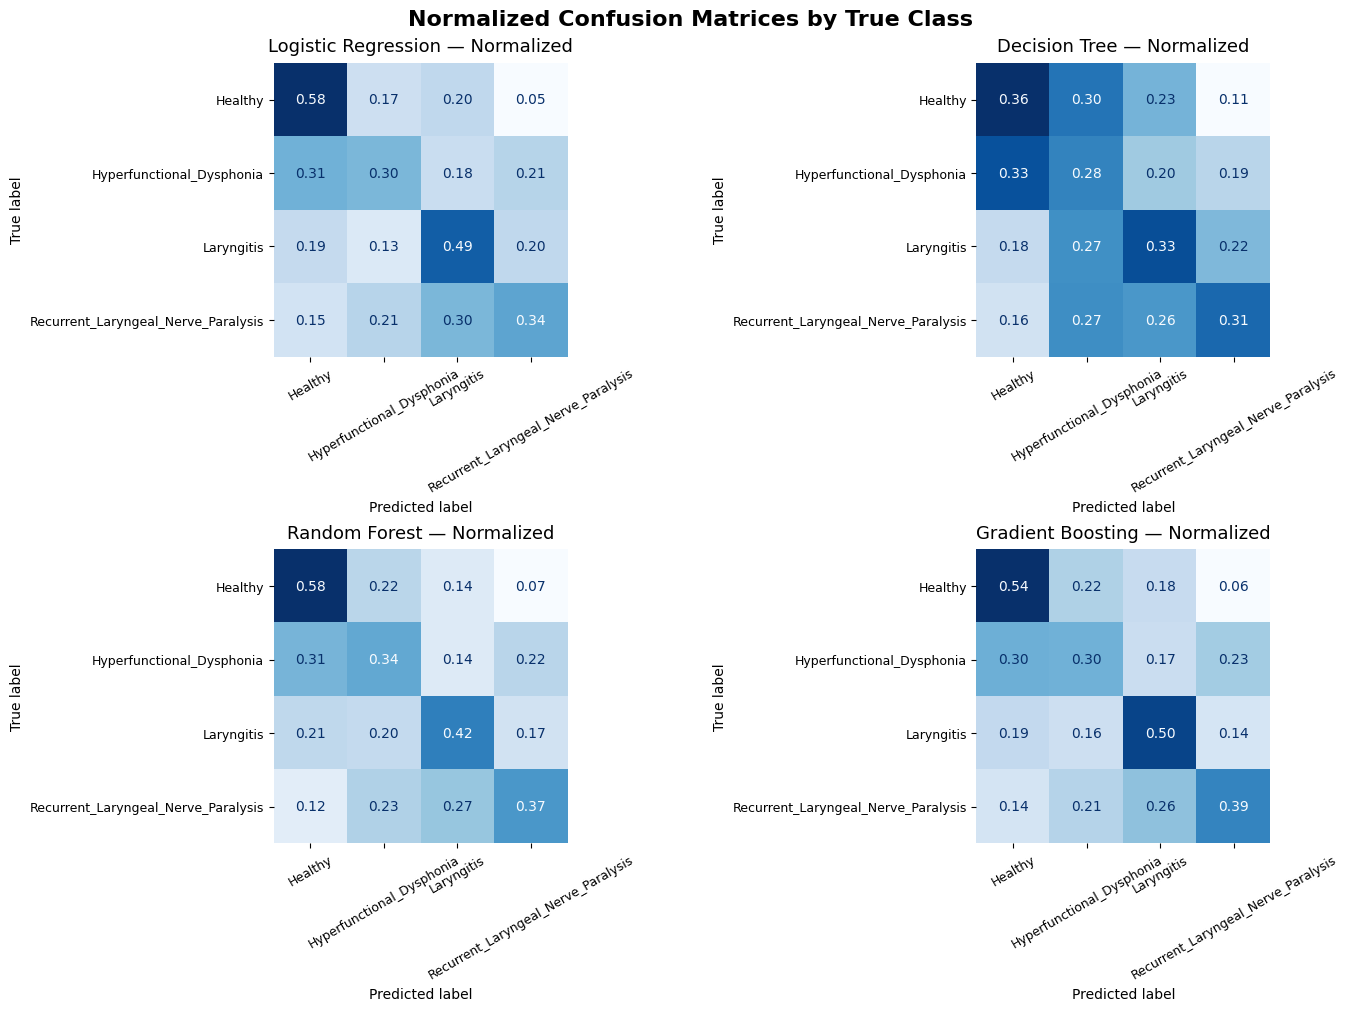

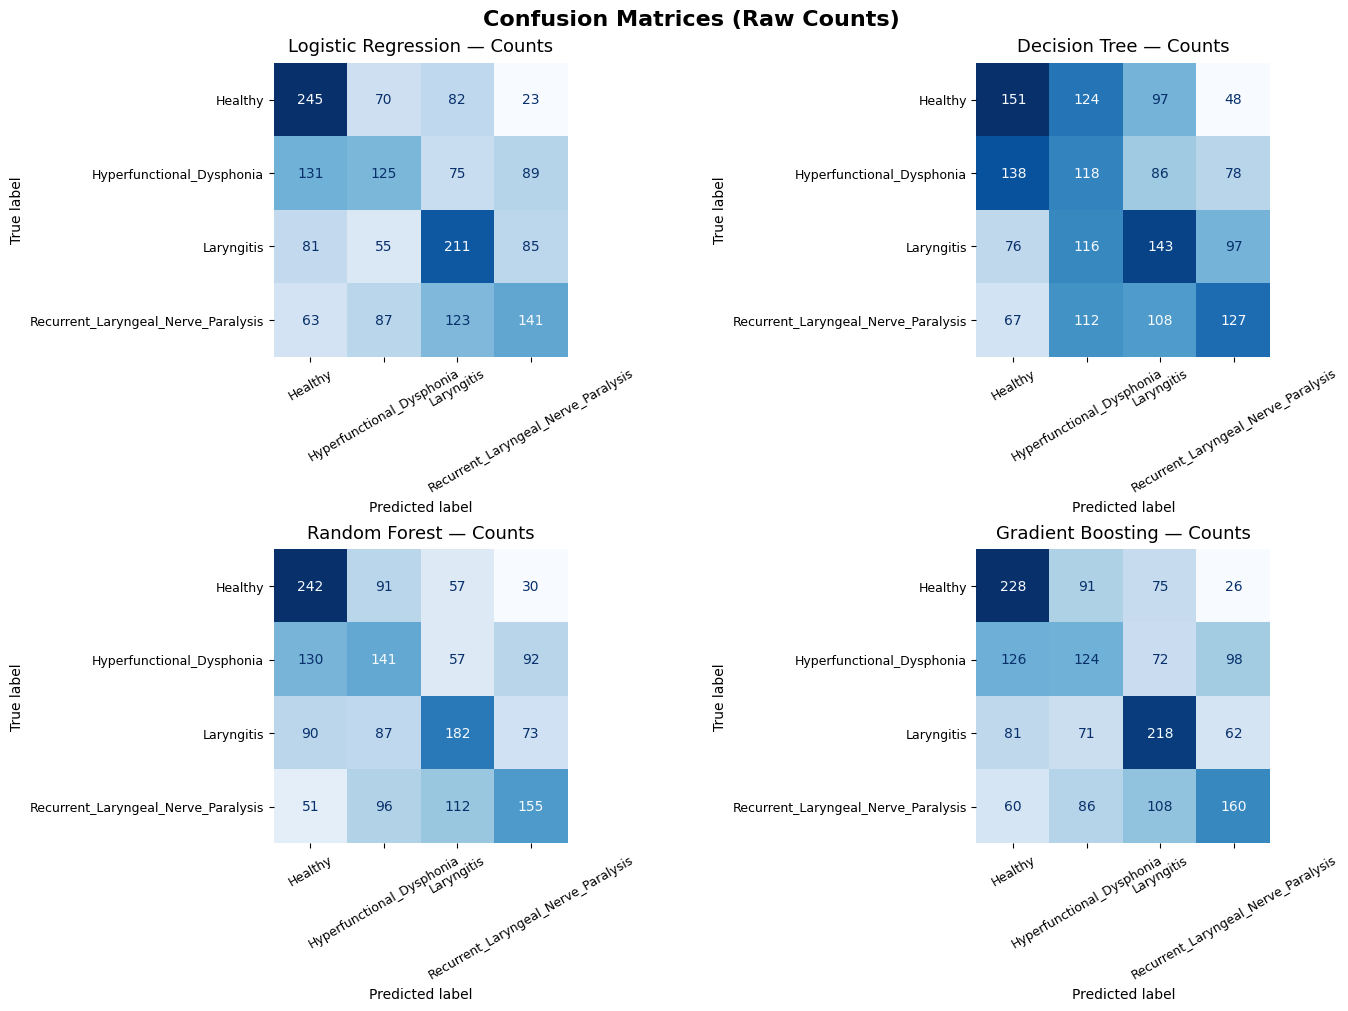

MODEL PERFORMANCE SUMMARY
              model  accuracy  balanced_accuracy  macro_F1
  Gradient Boosting  0.432977           0.432300  0.428578
Logistic Regression  0.428233           0.427490  0.420933
      Random Forest  0.427046           0.426899  0.423893
      Decision Tree  0.319692           0.319564  0.320586


In [43]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

FEATURES_CSV = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_features.csv")
df = pd.read_csv(FEATURES_CSV)

META = ["class","patient_id","vowel","condition","filename","filepath","sample_rate","duration_sec"]
X = df.drop(columns=[c for c in META if c in df.columns], errors="ignore").select_dtypes(include=[np.number])
y_str = df["class"].astype(str)

#Encode classes numerically
le = LabelEncoder()
y = le.fit_transform(y_str)


def patient_split(frame, test_size=0.25, random_state=42):
    #Split by patients, this ensures that no patient appears in both sets (train and set)
    #Stratified by class at the patient level, keep the same balance of classes, for each class (ex: healthy...), take some patients for training and some for testing

    rng = np.random.RandomState(random_state)
    train_pats, test_pats = set(), set()

    for cls, g in frame.groupby("class"):
        pats = g["patient_id"].astype(str).unique().tolist()
        rng.shuffle(pats)
        n_test = max(1, int(round(len(pats) * test_size)))
        test_pats |= set(pats[:n_test])
        train_pats |= set(pats[n_test:])

    train_idx = frame.index[frame["patient_id"].astype(str).isin(train_pats)]
    test_idx  = frame.index[frame["patient_id"].astype(str).isin(test_pats)]
    return train_idx, test_idx

train_idx, test_idx = patient_split(df, test_size=0.25, random_state=42)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Train patients: {df.loc[train_idx, 'patient_id'].nunique()} | "
      f"Test patients: {df.loc[test_idx, 'patient_id'].nunique()}")
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")


def make_pipeline(clf, k=None, scale=False):
    steps = [("imputer", SimpleImputer(strategy="mean"))]
    if k is not None:
        steps.append(("select", SelectKBest(f_classif, k=min(k, X_train.shape[1]))))
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)

#Train models
models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=3000, solver="saga", random_state=42),
        k=30, scale=True
    ),
    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(random_state=42), k=10
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=400, random_state=42, n_jobs=-1),
        k=None  #keep all the k's
    ),
    "Gradient Boosting": make_pipeline(
        GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
        k=None  #keep all the k's
    ),
}

y_preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_preds[name] = model.predict(X_test)
    acc = accuracy_score(y_test, y_preds[name])
    print(f"{name:<20} | Test Accuracy: {acc:.3f}")


labels_true = np.arange(len(le.classes_))
labels_display = list(le.classes_)

def plot_confusion(ax, y_true, y_pred, labels_true, labels_display, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels_true, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_display)
    fmt = ".2f" if normalize else "d"
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=fmt)
    ax.set_title(title, fontsize=13, pad=8)
    ax.tick_params(axis="x", labelrotation=30, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

#Normalized confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Normalized", normalize="true")
fig.suptitle("Normalized Confusion Matrices by True Class", fontsize=16, fontweight="bold")
plt.show()

#Raw confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Counts", normalize=None)
fig.suptitle("Confusion Matrices (Raw Counts)", fontsize=16, fontweight="bold")
plt.show()


summary = pd.DataFrame({
    "model": list(models.keys()),
    "accuracy": [accuracy_score(y_test, y_preds[m]) for m in models],
    "balanced_accuracy": [balanced_accuracy_score(y_test, y_preds[m]) for m in models],
    "macro_F1": [f1_score(y_test, y_preds[m], average="macro") for m in models]
})

print("MODEL PERFORMANCE SUMMARY")
print(summary.sort_values("accuracy", ascending=False).to_string(index=False))


PART II:

Now I am trying with more features

In [ ]:
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

DATASET_DIR = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_WAV")
OUTPUT_CSV  = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_features_def.csv")

CLASSES = ["Healthy", "Laryngitis", "Hyperfunctional_Dysphonia", "Recurrent_Laryngeal_Nerve_Paralysis"]

#Takes Pat ID
def parse_patient_id(filename: str) -> str:
    base = os.path.splitext(filename)[0]
    token = base.split("-")[0].split("_")[0]
    return token if token.isdigit() else "unknown"

def safe_mean(x):
    return float(np.nanmean(x)) if x is not None else np.nan #computes the average but ignores NaN values.

def safe_std(x):
    return float(np.nanstd(x)) if x is not None else np.nan #also ignore NaN values for std

#Extraction 
all_rows = []

for class_name in CLASSES:
    class_dir = os.path.join(DATASET_DIR, class_name)
    if not os.path.exists(class_dir):
        print(f"Missing folder: {class_dir}")
        continue

    files = [f for f in os.listdir(class_dir) if f.lower().endswith(".wav")]
    print(f"\nProcessing class: {class_name}  ({len(files)} files)")

    for i, filename in enumerate(files, start=1):
        fpath = os.path.join(class_dir, filename)

        #Load audio 
        try:
            y, sr = librosa.load(fpath, sr=None)
        except Exception:
            continue

        #Skip too-short/broken files (<0.1s)
        if sr is None or len(y) < max(1, sr // 10):
            continue

        if i % 100 == 0:
            print(".", end="", flush=True)

        #TIME DOMAIN 
        rms_v = librosa.feature.rms(y=y)[0]                         
        zcr_v = librosa.feature.zero_crossing_rate(y=y)[0]          

        rms_mean, rms_std = float(np.mean(rms_v)), float(np.std(rms_v))
        zcr_mean, zcr_std = float(np.mean(zcr_v)), float(np.std(zcr_v))

        #PITCH & JITTER 
        try:
            f0, voiced_flag, voiced_probs = librosa.pyin(y, fmin=50, fmax=400)
        except Exception:
            f0 = None

        f0_mean = safe_mean(f0)
        f0_std  = safe_std(f0)
        if f0 is not None:
            f0_valid = f0[~np.isnan(f0)]
            if f0_valid.size > 1 and np.nanmean(f0_valid) > 0:
                jitter = float(np.mean(np.abs(np.diff(f0_valid))) / np.mean(f0_valid))
            else:
                jitter = 0.0
        else:
            jitter = 0.0

        #SPECTRAL 
        spec_centroid_v = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        spec_bw_v       = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
        spec_flat_v     = librosa.feature.spectral_flatness(y=y)[0]
        spec_roll_v     = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)[0]

        spec_centroid_mean, spec_centroid_std = float(np.mean(spec_centroid_v)), float(np.std(spec_centroid_v))
        spec_bw_mean,       spec_bw_std       = float(np.mean(spec_bw_v)),       float(np.std(spec_bw_v))
        spec_flatness_mean, spec_flatness_std = float(np.mean(spec_flat_v)),     float(np.std(spec_flat_v))
        spec_rolloff_mean,  spec_rolloff_std  = float(np.mean(spec_roll_v)),     float(np.std(spec_roll_v))

        #MFCC 
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)          
        mfcc_means = np.mean(mfcc, axis=1)                         

        #CHROMA
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)            
        chroma_means = np.mean(chroma, axis=1)                      

        #SPECTRAL CONTRAST
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)    
        contrast_means = np.mean(contrast, axis=1)                  

        #COLLECT 
        feat = {
            #metadata/context (not part of the 54 features)
            "class": class_name,
            "filename": filename,
            "patient_id": parse_patient_id(filename),
            "sample_rate": sr,
            "duration_sec": len(y) / sr,

            #15 base acoustic scalars
            "rms_mean": rms_mean, "rms_std": rms_std,
            "zcr_mean": zcr_mean, "zcr_std": zcr_std,
            "f0_mean": float(f0_mean), "f0_std": float(f0_std), "jitter": float(jitter),
            "spec_centroid_mean": spec_centroid_mean, "spec_centroid_std": spec_centroid_std,
            "spec_bw_mean": spec_bw_mean, "spec_bw_std": spec_bw_std,
            "spec_flatness_mean": spec_flatness_mean, "spec_flatness_std": spec_flatness_std,
            "spec_rolloff_mean": spec_rolloff_mean, "spec_rolloff_std": spec_rolloff_std,
        }

        #for each of the 20 MFCC coefficients, take the average across all frames.
        for i_m in range(20):
            feat[f"mfcc_{i_m+1}_mean"] = float(mfcc_means[i_m])

        #same but for 12 chroma bins.
        for i_c in range(12):
            feat[f"chroma_{i_c+1}_mean"] = float(chroma_means[i_c])

        #same but for 7 spectral contrast bands.
        for i_k in range(7):
            feat[f"contrast_{i_k+1}_mean"] = float(contrast_means[i_k])

        #At this point: 15 + 20 + 12 + 7 = 54 acoustic features
        all_rows.append(feat)

    print(" Done")

df = pd.DataFrame(all_rows)
Path(os.path.dirname(OUTPUT_CSV)).mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_CSV, index=False)
acoustic_cols = [c for c in df.columns if c not in ("class","filename","patient_id","sample_rate","duration_sec")]


Processing class: Healthy  (3360 files)
................................. Done

Processing class: Laryngitis  (3360 files)
................................. Done

Processing class: Hyperfunctional_Dysphonia  (3360 files)
................................. Done

Processing class: Recurrent_Laryngeal_Nerve_Paralysis  (3342 files)
................................. Done


Training with DT, LG, GB and RF using SelectKbest and also GroupKFold CV

Train patients: 415 | Test patients: 140
Train samples: 10098 | Test samples: 3372
Logistic Regression  | Test Accuracy: 0.413
Decision Tree        | Test Accuracy: 0.335
Random Forest        | Test Accuracy: 0.442
Gradient Boosting    | Test Accuracy: 0.424

Chosen k per model (from GroupKFold CV):
  Logistic Regression  -> k = 54
  Decision Tree        -> k = 30
  Random Forest        -> k = 54
  Gradient Boosting    -> k = 54


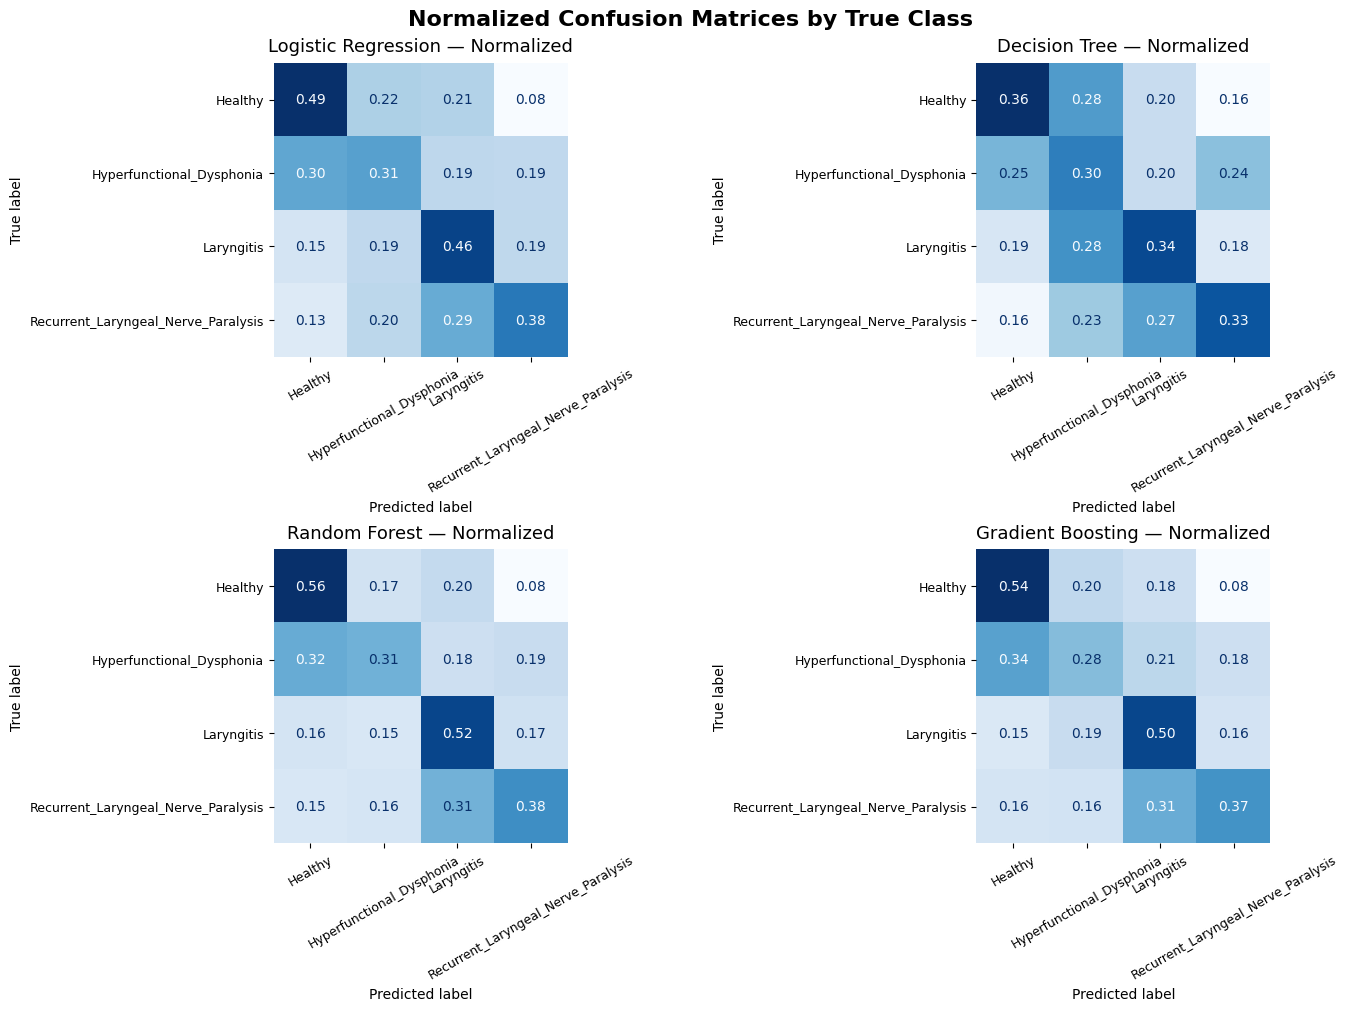

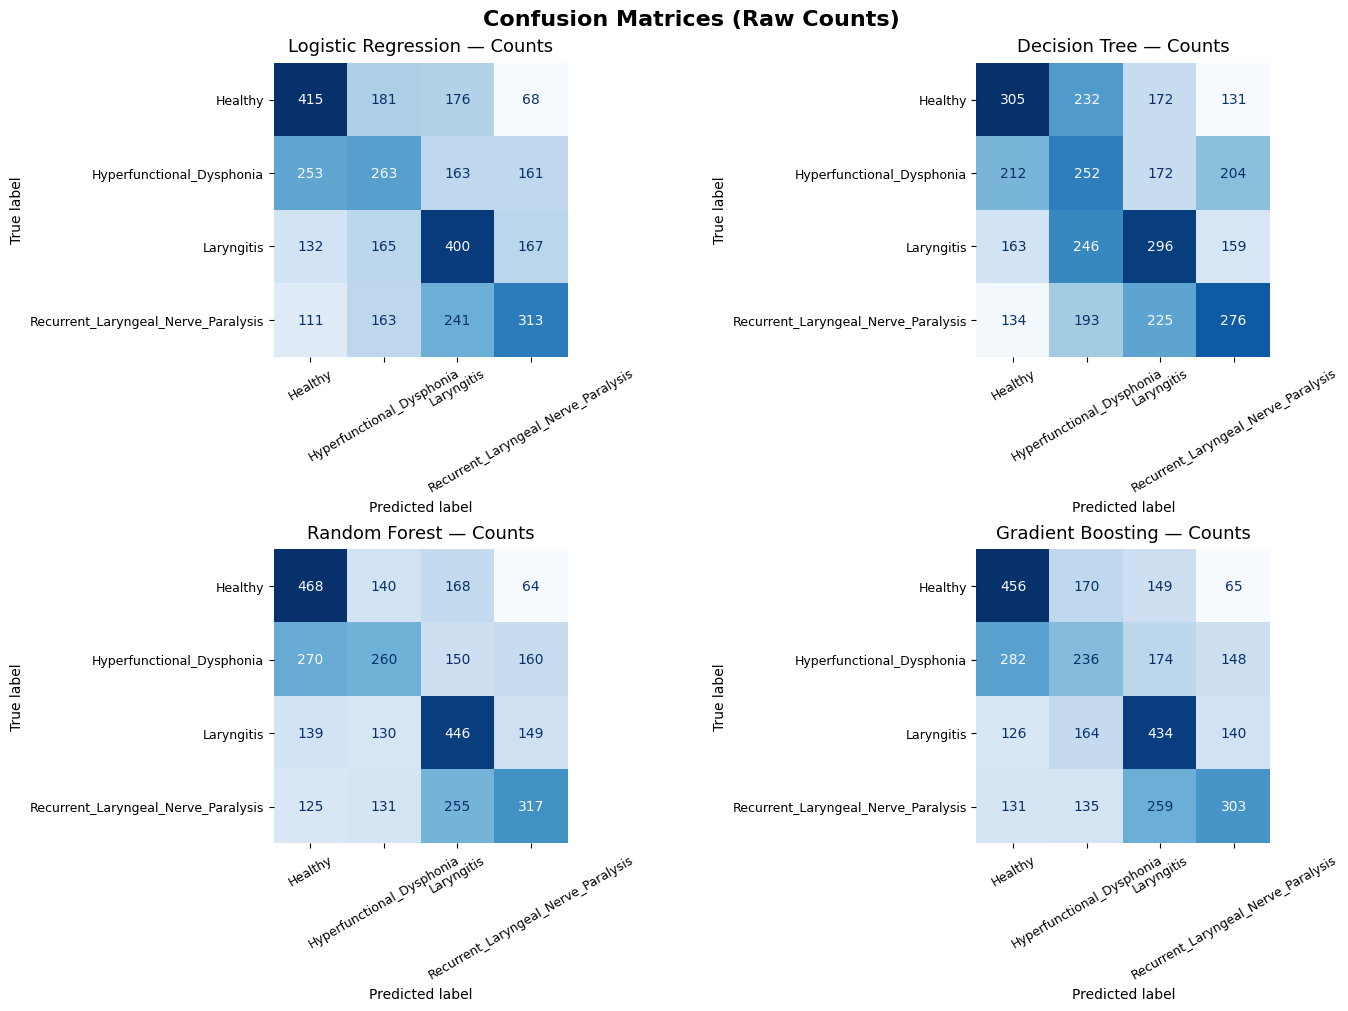

MODEL PERFORMANCE SUMMARY
              model  accuracy  balanced_accuracy  macro_F1
      Random Forest  0.442171           0.441430  0.436487
  Gradient Boosting  0.423784           0.423017  0.418141
Logistic Regression  0.412515           0.412031  0.410361
      Decision Tree  0.334816           0.334755  0.335626

TOP 15 FEATURES PER MODEL
Logistic Regression
spec_bw_mean          0.956029
spec_rolloff_mean     0.600879
mfcc_2_mean           0.545222
spec_centroid_mean    0.523900
contrast_7_mean       0.410528
mfcc_5_mean           0.352887
mfcc_1_mean           0.299827
contrast_3_mean       0.238195
spec_flatness_std     0.236114
spec_flatness_mean    0.218190
zcr_mean              0.202057
rms_mean              0.188805
contrast_2_mean       0.176013
mfcc_3_mean           0.174977
f0_mean               0.174079

Decision Tree
contrast_3_mean    0.077241
mfcc_9_mean        0.051082
contrast_1_mean    0.046892
rms_mean           0.040994
contrast_5_mean    0.040330
mfcc_3_mean 

In [45]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

#Load CSV 
OUTPUT_CSV = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_features_def.csv")
df = pd.read_csv(OUTPUT_CSV)

df["patient_id"] = df["patient_id"].astype(str)
df["class"] = df["class"].astype(str)

META = ["class", "patient_id", "filename", "sample_rate", "duration_sec"]
X = df.drop(columns=[c for c in META if c in df.columns], errors="ignore").select_dtypes(include=[np.number])
y_str = df["class"].astype(str)

le = LabelEncoder()
y = le.fit_transform(y_str)

#Fill NaNs (safe for SelectKBest)
X = X.fillna(X.mean())


def patient_split(frame, test_size=0.25, random_state=42):
    rng = np.random.RandomState(random_state)
    train_pats, test_pats = set(), set()
    #stratify by class at patient level
    for _, g in frame.groupby("class"):
        pats = g["patient_id"].astype(str).unique().tolist()
        rng.shuffle(pats)
        n_test = max(1, int(round(len(pats) * test_size)))
        test_pats |= set(pats[:n_test])
        train_pats |= set(pats[n_test:])
    train_idx = frame.index[frame["patient_id"].astype(str).isin(train_pats)]
    test_idx  = frame.index[frame["patient_id"].astype(str).isin(test_pats)]
    return train_idx, test_idx

train_idx, test_idx = patient_split(df, test_size=0.25, random_state=42)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Train patients: {df.loc[train_idx, 'patient_id'].nunique()} | Test patients: {df.loc[test_idx, 'patient_id'].nunique()}")
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

#Build pipelines; choose k with GroupKFold on TRAIN patients
groups_train = df.loc[train_idx, "patient_id"].astype(str)

n_unique_groups = groups_train.nunique()
n_splits = min(5, n_unique_groups)  #in case train has few patients
if n_splits < 2:
    raise ValueError("Not enough unique patients in the training set to perform GroupKFold CV.")
gkf = GroupKFold(n_splits=n_splits)

def make_pipe(base_clf, needs_scaler=False):
    steps = [("imputer", SimpleImputer(strategy="mean")),
             ("select", SelectKBest(score_func=f_classif))]
    if needs_scaler:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", base_clf))
    return Pipeline(steps)

#We'll test k in {10, 30, all}
all_k = [10, 30, X_train.shape[1]]

models_for_cv = {
    "Logistic Regression": {
        "pipe": make_pipe(LogisticRegression(max_iter=3000, solver="saga", random_state=42), needs_scaler=True),
        "param_grid": {"select__k": all_k},
    },
    "Decision Tree": {
        "pipe": make_pipe(DecisionTreeClassifier(random_state=42), needs_scaler=False),
        "param_grid": {"select__k": all_k},
    },
    "Random Forest": {
        "pipe": make_pipe(RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1), needs_scaler=False),
        "param_grid": {"select__k": all_k},
    },
    "Gradient Boosting": {
        "pipe": make_pipe(GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.05, max_depth=3,
            validation_fraction=0.1, n_iter_no_change=10, random_state=42
        ), needs_scaler=False),
        "param_grid": {"select__k": all_k},
    },
}

#Tune k via GroupKFold on training set, refit best on all training, test once
y_preds = {}
best_pipelines = {}
best_k_per_model = {}

for name, cfg in models_for_cv.items():
    gs = GridSearchCV(#GridSearchCV tests dif values of k using only the training set with GroupKFold.
        estimator=cfg["pipe"],
        param_grid=cfg["param_grid"],
        cv=gkf,
        scoring="accuracy",
        n_jobs=-1
    )
    gs.fit(X_train, y_train, groups=groups_train)
    best_pipelines[name] = gs.best_estimator_
    best_k_per_model[name] = gs.best_params_.get("select__k", None)

    #Now that the best k is chosen, we train the final model again using all the training data
    best_pipelines[name].fit(X_train, y_train)
    y_preds[name] = best_pipelines[name].predict(X_test)
    acc = accuracy_score(y_test, y_preds[name])

    
    print(f"{name:<20} | Test Accuracy: {acc:.3f}")

print("\nChosen k per model (from GroupKFold CV):")
for m, k in best_k_per_model.items():
    print(f"  {m:<20} -> k = {k}")


#Confusion matrices (normalized and raw)
labels_true = np.arange(len(le.classes_))
labels_display = list(le.classes_)

def plot_confusion(ax, y_true, y_pred, labels_true, labels_display, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels_true, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_display)
    fmt = ".2f" if normalize else "d"
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=fmt)
    ax.set_title(title, fontsize=13, pad=8)
    ax.tick_params(axis="x", labelrotation=30, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

#Normalized
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Normalized", normalize="true")
fig.suptitle("Normalized Confusion Matrices by True Class", fontsize=16, fontweight="bold")
plt.show()

#Raw counts
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Counts", normalize=None)
fig.suptitle("Confusion Matrices (Raw Counts)", fontsize=16, fontweight="bold")
plt.show()


summary = pd.DataFrame({
    "model": list(best_pipelines.keys()),
    "accuracy": [accuracy_score(y_test, y_preds[m]) for m in best_pipelines],
    "balanced_accuracy": [balanced_accuracy_score(y_test, y_preds[m]) for m in best_pipelines],
    "macro_F1": [f1_score(y_test, y_preds[m], average="macro") for m in best_pipelines],
})
print("MODEL PERFORMANCE SUMMARY")
print(summary.sort_values("accuracy", ascending=False).to_string(index=False))


def _selected_feature_names(pipe, X_columns):
    names = np.array(X_columns, dtype=object)
    if "select" in pipe.named_steps:
        mask = pipe.named_steps["select"].get_support()
        if len(mask) != len(names):
            m = min(len(mask), len(names))
            mask = mask[:m]
            names = names[:m]
        names = names[mask]
    return names

def _top_features_series(pipe, X_columns, topn=15):
    names = _selected_feature_names(pipe, X_columns)
    clf = pipe.named_steps["clf"]

    if hasattr(clf, "feature_importances_"):
        importances = np.asarray(clf.feature_importances_, dtype=float)
        m = min(len(importances), len(names))
        return pd.Series(importances[:m], index=names[:m]).sort_values(ascending=False).head(topn)

    if hasattr(clf, "coef_"):
        coefs = np.asarray(clf.coef_, dtype=float)
        weights = np.mean(np.abs(coefs), axis=0) if coefs.ndim == 2 else np.abs(coefs)
        m = min(len(weights), len(names))
        return pd.Series(weights[:m], index=names[:m]).sort_values(ascending=False).head(topn)

    return pd.Series(dtype=float)


print("\nTOP 15 FEATURES PER MODEL")
for name, pipe in best_pipelines.items():
    try:
        s = _top_features_series(pipe, X_train.columns, topn=15)
        if s.empty:
            print(f"{name}\n  (No coefficients/importances available for this estimator.)")
        else:
            print(f"{name}\n{s.to_string()}\n")
    except Exception as e:
        print(f"{name}\n  Top features unavailable: {e}\n")

PART III:


in this part I try the .nsp files only

In [ ]:
DATASET_DIR = Path(str(DATA_ROOT / "Speech_pathologies_dataset"))  
OUTPUT_DIR  = Path(str(OUTPUT_ROOT / "Speech_pathologies_dataset_balanced_NSP"))
CLASSES = ["Healthy", "Laryngitis", "Hyperfunctional_Dysphonia", "Recurrent_Laryngeal_Nerve_Paralysis"]
TARGET_PATIENTS = 140
DO_COPY = True

def patient_id_from_name(filename: str) -> str:
    """Digits before '-' are patient_id, else 'unknown'."""
    base = os.path.basename(filename)
    pid = base.split("-")[0]
    return pid if pid.isdigit() else "unknown"

def balance_nsp_():
    patient_nsp_paths = {c: {} for c in CLASSES}  #class -> patient -> [paths]

    for class_name in CLASSES:
        cdir = DATASET_DIR / class_name
        if not cdir.is_dir():
            print(f"[MISS] {cdir}")
            continue

        for f in cdir.iterdir():
            if f.is_file() and f.name.lower().endswith(".nsp"):
                pid = patient_id_from_name(f.name)
                patient_nsp_paths[class_name].setdefault(pid, []).append(f)

    random.seed(42)
    kept_patients = {}
    for class_name in CLASSES:
        patients = list(patient_nsp_paths[class_name].keys())
        kept_patients[class_name] = (
            patients if len(patients) <= TARGET_PATIENTS
            else random.sample(patients, TARGET_PATIENTS)
        )

    if DO_COPY:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    for class_name in CLASSES:
        out_cdir = OUTPUT_DIR / class_name
        copied = 0

        if DO_COPY:
            out_cdir.mkdir(parents=True, exist_ok=True)

            for pid in kept_patients[class_name]:
                for src in patient_nsp_paths[class_name].get(pid, []):
                    dst = out_cdir / src.name
                    shutil.copy2(src, dst)
                    copied += 1

        print(f"[{class_name}] Copied {copied} NSP files → {out_cdir}")

balance_nsp_()

[Healthy] Copied 1680 NSP files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_NSP\Healthy
[Laryngitis] Copied 1680 NSP files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_NSP\Laryngitis
[Hyperfunctional_Dysphonia] Copied 1680 NSP files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_NSP\Hyperfunctional_Dysphonia
[Recurrent_Laryngeal_Nerve_Paralysis] Copied 1671 NSP files → <PROJECT_ROOT>/Speech_pathologies_dataset_balanced_NSP\Recurrent_Laryngeal_Nerve_Paralysis


Conversion from .nsp to .wav to use librosa

In [ ]:


root_dir = Path(str(OUTPUT_ROOT / "Speech_pathologies_dataset_balanced_NSP"))
output_dir = Path(str(OUTPUT_ROOT / "Speech_pathologies_dataset_NSP_WAV"))
output_dir.mkdir(parents=True, exist_ok=True)

if not shutil.which("ffmpeg"):
    raise RuntimeError(
        "FFmpeg is not installed or not in PATH.\n"
        "Install it with:\n"
        "    winget install ffmpeg\n"
        "Then restart your terminal and try again."
    )

#We find all .nsp files
nsp_files = list(root_dir.rglob("*.nsp"))
if not nsp_files:
    print("No .nsp files found in the dataset folder.")
else:
    print(f"Found {len(nsp_files)} .nsp files to convert.\n")


converted = 0
failed = 0

for nsp_file in nsp_files:
    rel_path = nsp_file.relative_to(root_dir).with_suffix(".wav")
    wav_path = output_dir / rel_path
    wav_path.parent.mkdir(parents=True, exist_ok=True)

    #FFmpeg command
    cmd = [
        "ffmpeg",
        "-y",               #overwrite output
        "-i", str(nsp_file),#input file
        "-ac", "1",         #mono
        "-ar", "44100",     #44.1 kHz
        str(wav_path)
    ]

    #Run FFmpeg
    result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    if result.returncode == 0 and wav_path.exists() and wav_path.stat().st_size > 0:
        converted += 1
        print(f"Converted: {nsp_file.name}")
    else:
        failed += 1
        print(f"Failed: {nsp_file.name}")
        print(result.stderr.splitlines()[-1])

print(f"\nDone! Converted: {converted} | Failed: {failed}")
print(f"WAV files saved in: {output_dir}")



Individual conversion filenames omitted from saved output. Re-run the cell with your own dataset to see conversion logs.


Feature selection, and instead of having one row per recording, the dataset now has one single row per patient

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)  #sklearn, pandas
warnings.filterwarnings("ignore", category=RuntimeWarning)  #numpy, scipy

DATASET_DIR = str(OUTPUT_ROOT / "Speech_pathologies_dataset_NSP_WAV")
OUTPUT_CSV  = str(OUTPUT_ROOT / "Speech_pathologies_dataset_NSP_features.csv")  

CLASSES = [
    "Healthy",
    "Laryngitis",
    "Hyperfunctional_Dysphonia",
    "Recurrent_Laryngeal_Nerve_Paralysis",
]


def parse_patient_id(filename: str) -> str:
    base = os.path.splitext(os.path.basename(filename))[0]
    token = base.split("-")[0].split("_")[0]
    return token if token.isdigit() else "unknown"

def to_mono_float32(y):
    y = np.asarray(y)
    if y.ndim == 2:
        y = y.mean(axis=1)
    if np.issubdtype(y.dtype, np.integer):
        y = y.astype(np.float32) / np.iinfo(y.dtype).max
    else:
        y = y.astype(np.float32, copy=False)
    return np.nan_to_num(y)

def load_audio(path):
    try:
        y, sr = librosa.load(path, sr=None, mono=True)
    except:
        y, sr = sf.read(path, always_2d=False)
    return to_mono_float32(y), int(sr)

def list_wavs(folder):
    files = []
    for root, _, f in os.walk(folder):
        for name in f:
            if name.lower().endswith(".wav"):
                files.append(os.path.join(root, name))
    return files


rows = []

for cls in CLASSES:
    class_dir = os.path.join(DATASET_DIR, cls)
    files = list_wavs(class_dir)

    print(f"\nProcessing class: {cls}  ({len(files)} files)")
    step = max(1, len(files) // 33)
    d = 0

    for i, fpath in enumerate(files, 1):
        try:
            y, sr = load_audio(fpath)
        except:
            continue

        if len(y) < max(2048, int(sr * 0.10)):
            continue

        #Time
        rms_v = librosa.feature.rms(y=y)[0]
        zcr_v = librosa.feature.zero_crossing_rate(y=y)[0]

        #Spectral
        sc = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        sb = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
        sfv = librosa.feature.spectral_flatness(y=y)[0]
        sro = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]

        #MFCC / Chroma / Contrast
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)

        feat = {
            "class": cls,
            "patient_id": parse_patient_id(fpath),
            "duration_sec": len(y)/sr,
            "sample_rate": sr,
            "rms_mean": np.mean(rms_v), "rms_std": np.std(rms_v),
            "zcr_mean": np.mean(zcr_v), "zcr_std": np.std(zcr_v),
            "f0_mean": np.nan, "f0_std": np.nan, "jitter": np.nan,
            "spec_centroid_mean": np.mean(sc), "spec_centroid_std": np.std(sc),
            "spec_bw_mean": np.mean(sb), "spec_bw_std": np.std(sb),
            "spec_flat_mean": np.mean(sfv), "spec_flat_std": np.std(sfv),
            "spec_roll_mean": np.mean(sro), "spec_roll_std": np.std(sro),
        }

        for j in range(20):
            feat[f"mfcc_{j+1}_mean"] = float(np.mean(mfcc[j]))
        for j in range(12):
            feat[f"chroma_{j+1}_mean"] = float(np.mean(chroma[j]))
        for j in range(7):
            feat[f"contrast_{j+1}_mean"] = float(np.mean(contrast[j]))

        rows.append(feat)

        if i % step == 0:
            print(".", end="", flush=True)
            d += 1

    if d == 0: print("."*min(33, len(files)), end="")
    print(" Done")

file_df = pd.DataFrame(rows)


#instead of having one row per recording, the dataset now has one single row per patient
if file_df.empty:
    patient_df = pd.DataFrame(columns=["patient_id","class"])
else:
    numeric = file_df.select_dtypes(include=np.number).columns

    patient_df = (
        file_df.groupby(["patient_id","class"], as_index=False)[numeric]
              .mean()
    )

patient_df.to_csv(OUTPUT_CSV, index=False)


Processing class: Healthy  (1680 files)
................................. Done

Processing class: Laryngitis  (1680 files)
................................. Done

Processing class: Hyperfunctional_Dysphonia  (1680 files)
................................. Done

Processing class: Recurrent_Laryngeal_Nerve_Paralysis  (1671 files)
................................. Done


Training with DT, LG, GB and RF using SelectKbest and also GroupKFold CV. 

Train patients: 415 | Test patients: 140
Train samples: 421 | Test samples: 141
Logistic Regression  | Test Accuracy: 0.440
Decision Tree        | Test Accuracy: 0.355
Random Forest        | Test Accuracy: 0.426
Gradient Boosting    | Test Accuracy: 0.404

Chosen k per model (from GroupKFold CV):
  Logistic Regression  -> k = 54
  Decision Tree        -> k = 54
  Random Forest        -> k = 54
  Gradient Boosting    -> k = 10


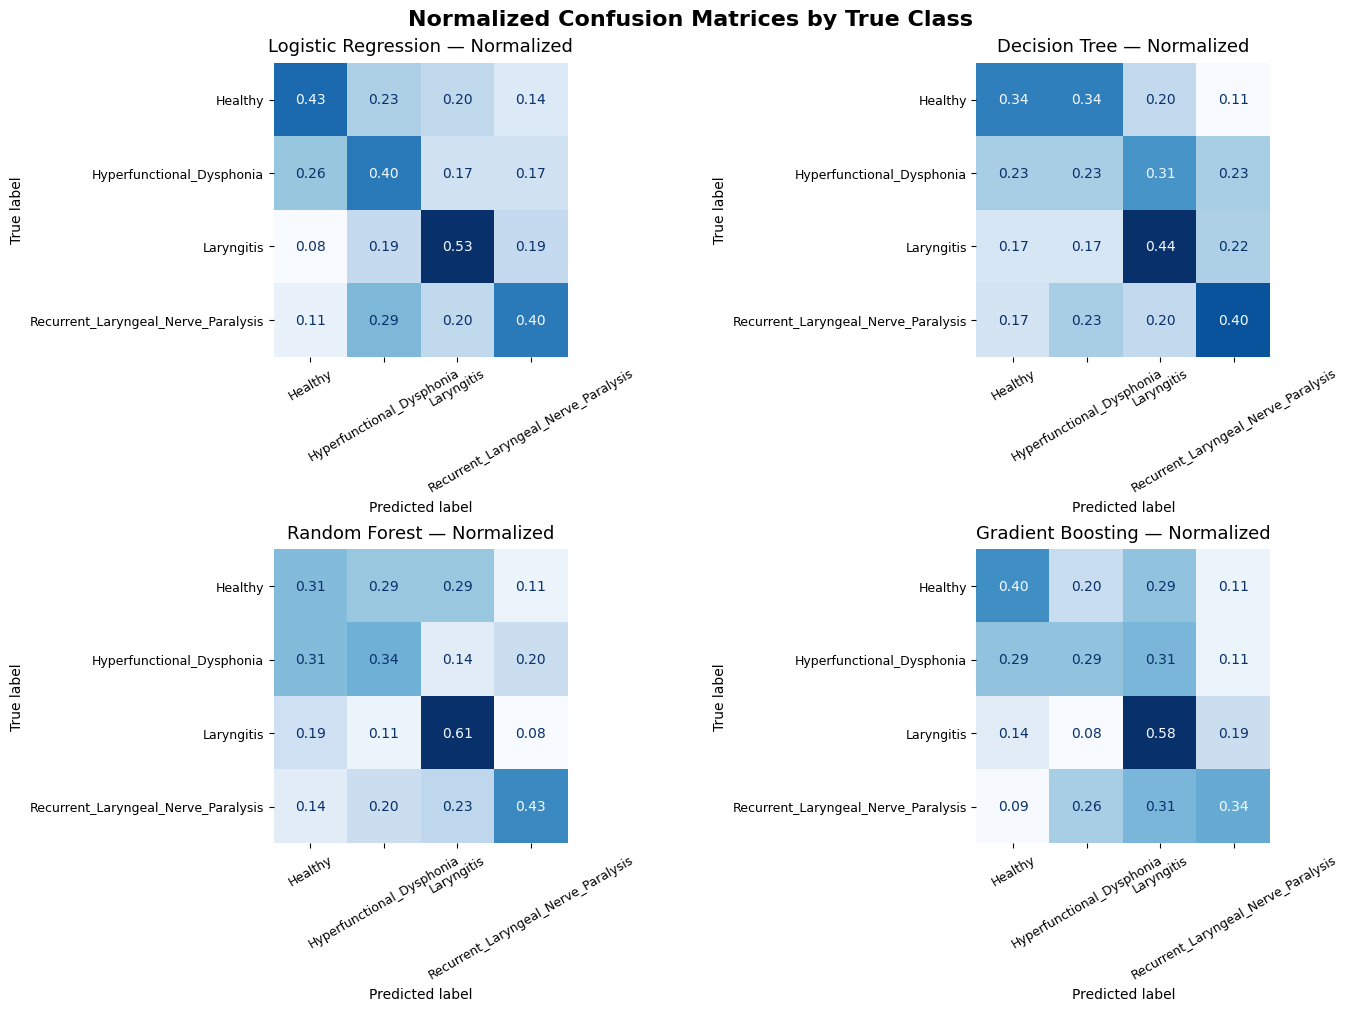

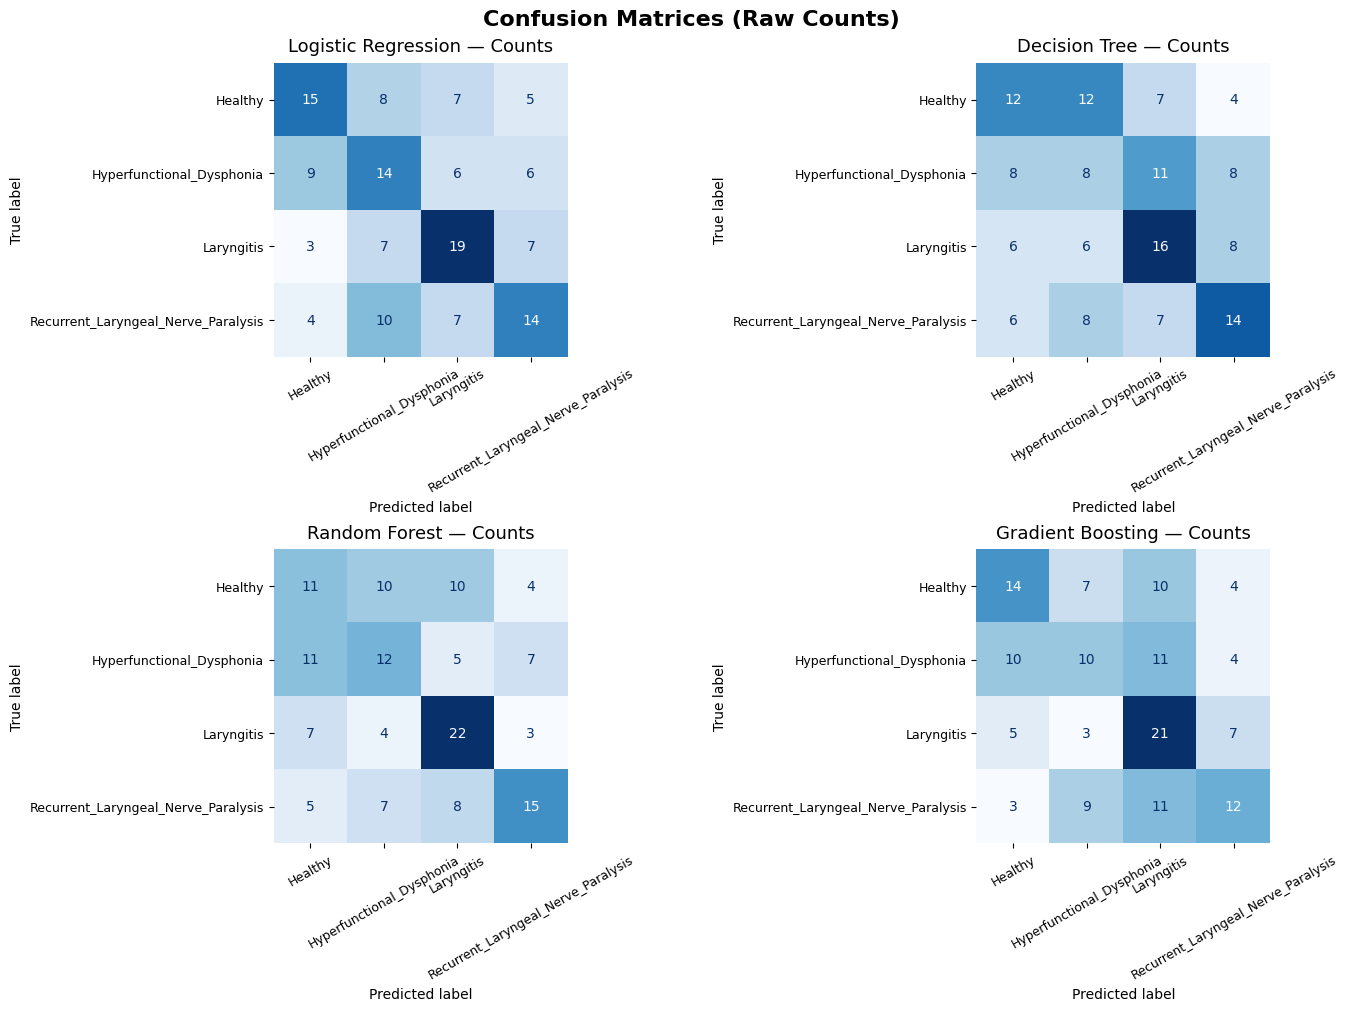

MODEL PERFORMANCE SUMMARY
              model  accuracy  balanced_accuracy  macro_F1
Logistic Regression  0.439716           0.439087  0.439375
      Random Forest  0.425532           0.424206  0.420935
  Gradient Boosting  0.404255           0.402976  0.397354
      Decision Tree  0.354610           0.353968  0.352869

TOP 15 FEATURES PER MODEL

Logistic Regression (features used after SelectKBest: 51)
        feature    score
         jitter 0.857406
    spec_bw_std 0.756690
 spec_roll_mean 0.622413
 chroma_12_mean 0.561391
   spec_bw_mean 0.472736
    mfcc_6_mean 0.469066
contrast_1_mean 0.434928
  chroma_4_mean 0.431637
  spec_flat_std 0.422076
   mfcc_16_mean 0.398144
         f0_std 0.390353
   mfcc_14_mean 0.379816
 chroma_11_mean 0.378820
       zcr_mean 0.370802
    mfcc_3_mean 0.349519

Decision Tree (features used after SelectKBest: 51)
        feature    score
contrast_3_mean 0.091682
 chroma_11_mean 0.071367
contrast_2_mean 0.050860
         f0_std 0.044903
    mfcc_2_mean

In [46]:

OUTPUT_CSV = str(OUTPUT_ROOT / "Speech_pathologies_dataset_NSP_features.csv")

df = pd.read_csv(OUTPUT_CSV)
df["patient_id"] = df["patient_id"].astype(str)
df["class"] = df["class"].astype(str)

META = ["class", "patient_id", "filename", "sample_rate", "duration_sec"]
X = df.drop(columns=[c for c in META if c in df.columns], errors="ignore").select_dtypes(include=[np.number])
y_str = df["class"].astype(str)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y_str)

#Fill NaNs 
X = X.fillna(X.mean())

#Patient-wise split and stratification

def patient_split(frame, test_size=0.25, random_state=42):
    rng = np.random.RandomState(random_state)
    train_pats, test_pats = set(), set()
    for _, g in frame.groupby("class"):
        pats = g["patient_id"].astype(str).unique().tolist()
        rng.shuffle(pats)
        n_test = max(1, int(round(len(pats) * test_size)))
        test_pats |= set(pats[:n_test])
        train_pats |= set(pats[n_test:])
    train_idx = frame.index[frame["patient_id"].astype(str).isin(train_pats)]
    test_idx  = frame.index[frame["patient_id"].astype(str).isin(test_pats)]
    return train_idx, test_idx

train_idx, test_idx = patient_split(df, test_size=0.25, random_state=42)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Train patients: {df.loc[train_idx, 'patient_id'].nunique()} | Test patients: {df.loc[test_idx, 'patient_id'].nunique()}")
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")


def make_pipe(base_clf, needs_scaler=False):
    steps = [("imputer", SimpleImputer(strategy="mean")),
             ("select", SelectKBest(score_func=f_classif, k=10))]  #k will be tuned
    if needs_scaler:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", base_clf))
    return Pipeline(steps)


models_for_cv = {
    "Logistic Regression": {
        "pipe": make_pipe(LogisticRegression(max_iter=3000, solver="saga", random_state=42), needs_scaler=True),
        "param_grid": {"select__k": [10, 30, X_train.shape[1]]},
    },
    "Decision Tree": {
        "pipe": make_pipe(DecisionTreeClassifier(random_state=42), needs_scaler=False),
        "param_grid": {"select__k": [10, 30, X_train.shape[1]]},
    },
    "Random Forest": {
        "pipe": make_pipe(RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1), needs_scaler=False),
        "param_grid": {"select__k": [10, 30, X_train.shape[1]]},
    },
    "Gradient Boosting": {
        "pipe": make_pipe(GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.05, max_depth=3,
            validation_fraction=0.1, n_iter_no_change=10, random_state=42
        ), needs_scaler=False),
        "param_grid": {"select__k": [10, 30, X_train.shape[1]]},
    },
}

#Patient-aware CV on training patients only
groups_train = df.loc[train_idx, "patient_id"].astype(str)
n_unique_groups = groups_train.nunique()
n_splits = max(2, min(5, n_unique_groups))
gkf = GroupKFold(n_splits=n_splits)


#Tune k per model (GroupKFold), refit on all training, evaluate once on hold-out test
best_pipelines = {}
best_k_per_model = {}
y_preds = {}

for name, cfg in models_for_cv.items():
    gs = GridSearchCV(
        estimator=cfg["pipe"],
        param_grid=cfg["param_grid"],
        cv=gkf,
        scoring="accuracy",
        n_jobs=-1
    )
    gs.fit(X_train, y_train, groups=groups_train)
    best_pipelines[name] = gs.best_estimator_
    best_k_per_model[name] = gs.best_params_.get("select__k", None)

    #Refit best on full training set and test once
    best_pipelines[name].fit(X_train, y_train)
    y_preds[name] = best_pipelines[name].predict(X_test)
    acc = accuracy_score(y_test, y_preds[name])
    print(f"{name:<20} | Test Accuracy: {acc:.3f}")

print("\nChosen k per model (from GroupKFold CV):")
for m, k in best_k_per_model.items():
    print(f"  {m:<20} -> k = {k}")


#Confusion matrices (normalized and raw)
labels_true = np.arange(len(le.classes_))
labels_display = list(le.classes_)

def plot_confusion(ax, y_true, y_pred, labels_true, labels_display, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels_true, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_display)
    fmt = ".2f" if normalize else "d"
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=fmt)
    ax.set_title(title, fontsize=13, pad=8)
    ax.tick_params(axis="x", labelrotation=30, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Normalized", normalize="true")
fig.suptitle("Normalized Confusion Matrices by True Class", fontsize=16, fontweight="bold")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Counts", normalize=None)
fig.suptitle("Confusion Matrices (Raw Counts)", fontsize=16, fontweight="bold")
plt.show()


summary = pd.DataFrame({
    "model": list(best_pipelines.keys()),
    "accuracy": [accuracy_score(y_test, y_preds[m]) for m in best_pipelines],
    "balanced_accuracy": [balanced_accuracy_score(y_test, y_preds[m]) for m in best_pipelines],
    "macro_F1": [f1_score(y_test, y_preds[m], average="macro") for m in best_pipelines],
})

print("MODEL PERFORMANCE SUMMARY")
print(summary.sort_values("accuracy", ascending=False).to_string(index=False))


def selected_cols_and_k(pipeline, X_columns):
    names = np.array(X_columns, dtype=object)
    if "select" in pipeline.named_steps:
        mask = pipeline.named_steps["select"].get_support()
        m = min(len(mask), len(names))
        mask = mask[:m]
        names = names[:m]
        names = names[mask]
        k_used = int(mask.sum())
    else:
        k_used = len(names)
    return names, k_used

def top_features_series(pipeline, X_columns, topn=15):
    cols, _ = selected_cols_and_k(pipeline, X_columns)
    clf = pipeline.named_steps["clf"]

    if hasattr(clf, "feature_importances_"):
        importances = np.asarray(clf.feature_importances_, dtype=float)
        m = min(len(importances), len(cols))
        return pd.Series(importances[:m], index=cols[:m]).sort_values(ascending=False).head(topn)

    if hasattr(clf, "coef_"):
        coefs = np.asarray(clf.coef_, dtype=float)
        weights = np.mean(np.abs(coefs), axis=0) if coefs.ndim == 2 else np.abs(coefs)
        m = min(len(weights), len(cols))
        return pd.Series(weights[:m], index=cols[:m]).sort_values(ascending=False).head(topn)

    return pd.Series(dtype=float)


print("\nTOP 15 FEATURES PER MODEL")
for name, pipe in best_pipelines.items():
    cols_used, k_used = selected_cols_and_k(pipe, X_train.columns)
    print(f"\n{name} (features used after SelectKBest: {k_used})")
    s = top_features_series(pipe, X_train.columns, topn=15)
    if s.empty:
        print("  (No coefficients/importances available for this estimator.)")
    else:
        top_df = s.reset_index()
        top_df.columns = ["feature", "score"]
        print(top_df.to_string(index=False))


fitted_models = {name: pipe for name, pipe in best_pipelines.items()}
best_row = summary.sort_values("accuracy", ascending=False).iloc[0]
best_name = best_row["model"]
best_pipeline = fitted_models[best_name]

MODEL_PATH = str(OUTPUT_ROOT / "trained_model_NSP.pkl")
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
joblib.dump(best_pipeline, MODEL_PATH)
print(f"\nSaved best model: {best_name} → {MODEL_PATH}")

Now I combine both .egg and .nsp files in the training...let's see what happens. 

First I have to create another csv for the .egg files, patient organized:

In [ ]:

warnings.filterwarnings("ignore", category=UserWarning)  #sklearn, pandas
warnings.filterwarnings("ignore", category=RuntimeWarning)  #numpy, scipy


DATASET_DIR = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_WAV")
OUTPUT_CSV  = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_features_pat.csv")  

CLASSES = [
    "Healthy",
    "Laryngitis",
    "Hyperfunctional_Dysphonia",
    "Recurrent_Laryngeal_Nerve_Paralysis",
]

def parse_patient_id(filename: str) -> str:
    base = os.path.splitext(os.path.basename(filename))[0]
    token = base.split("-")[0].split("_")[0]
    return token if token.isdigit() else "unknown"

def to_mono_float32(y):
    y = np.asarray(y)
    if y.ndim == 2:
        y = y.mean(axis=1)
    if np.issubdtype(y.dtype, np.integer):
        y = y.astype(np.float32) / np.iinfo(y.dtype).max
    else:
        y = y.astype(np.float32, copy=False)
    return np.nan_to_num(y)

def load_audio(path):
    try:
        y, sr = librosa.load(path, sr=None, mono=True)
    except:
        y, sr = sf.read(path, always_2d=False)
    return to_mono_float32(y), int(sr)

def list_wavs(folder):
    files = []
    for root, _, f in os.walk(folder):
        for name in f:
            if name.lower().endswith(".wav"):
                files.append(os.path.join(root, name))
    return files


#we extract features
rows = []

for cls in CLASSES:
    class_dir = os.path.join(DATASET_DIR, cls)
    files = list_wavs(class_dir)

    print(f"\nProcessing class: {cls}  ({len(files)} files)")
    step = max(1, len(files) // 33)
    d = 0

    for i, fpath in enumerate(files, 1):
        try:
            y, sr = load_audio(fpath)
        except:
            continue

        if len(y) < max(2048, int(sr * 0.10)):
            continue

        #Time
        rms_v = librosa.feature.rms(y=y)[0]
        zcr_v = librosa.feature.zero_crossing_rate(y=y)[0]

        #Spectral
        sc  = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        sb  = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
        sfv = librosa.feature.spectral_flatness(y=y)[0]
        sro = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)[0]

        #MFCC / Chroma / Contrast
        mfcc    = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        chroma  = librosa.feature.chroma_stft(y=y, sr=sr)
        contrast= librosa.feature.spectral_contrast(y=y, sr=sr)

        feat = {
            "class": cls,
            "patient_id": parse_patient_id(fpath),
            "duration_sec": len(y)/sr,
            "sample_rate": sr,
            "rms_mean": np.mean(rms_v), "rms_std": np.std(rms_v),
            "zcr_mean": np.mean(zcr_v), "zcr_std": np.std(zcr_v),
            "f0_mean": np.nan, "f0_std": np.nan, "jitter": np.nan,
            "spec_centroid_mean": np.mean(sc),  "spec_centroid_std": np.std(sc),
            "spec_bw_mean": np.mean(sb),        "spec_bw_std": np.std(sb),
            "spec_flat_mean": np.mean(sfv),     "spec_flat_std": np.std(sfv),
            "spec_roll_mean": np.mean(sro),     "spec_roll_std": np.std(sro),
        }

        for j in range(20):
            feat[f"mfcc_{j+1}_mean"] = float(np.mean(mfcc[j]))
        for j in range(12):
            feat[f"chroma_{j+1}_mean"] = float(np.mean(chroma[j]))
        for j in range(7):
            feat[f"contrast_{j+1}_mean"] = float(np.mean(contrast[j]))

        rows.append(feat)

        if i % step == 0:
            print(".", end="", flush=True)
            d += 1

    if d == 0: print("."*min(33, len(files)), end="")
    print(" Done")

file_df = pd.DataFrame(rows)


#PATIENT-LEVEL MEAN AGGREGATION
if file_df.empty:
    patient_df = pd.DataFrame(columns=["patient_id","class"])
else:
    numeric = file_df.select_dtypes(include=np.number).columns
    patient_df = (
        file_df.groupby(["patient_id","class"], as_index=False)[numeric]
              .mean()
    )

patient_df.to_csv(OUTPUT_CSV, index=False)


Processing class: Healthy  (3360 files)
................................. Done

Processing class: Laryngitis  (3360 files)
................................. Done

Processing class: Hyperfunctional_Dysphonia  (3360 files)
................................. Done

Processing class: Recurrent_Laryngeal_Nerve_Paralysis  (3342 files)
................................. Done


Training, fusing the two csv, the EGG ones and the NSP:

Train patients: 415 | Test patients: 140
Train samples: 421 | Test samples: 141
Logistic Regression  | Test Accuracy: 0.433
Decision Tree        | Test Accuracy: 0.383
Random Forest        | Test Accuracy: 0.504
Gradient Boosting    | Test Accuracy: 0.482


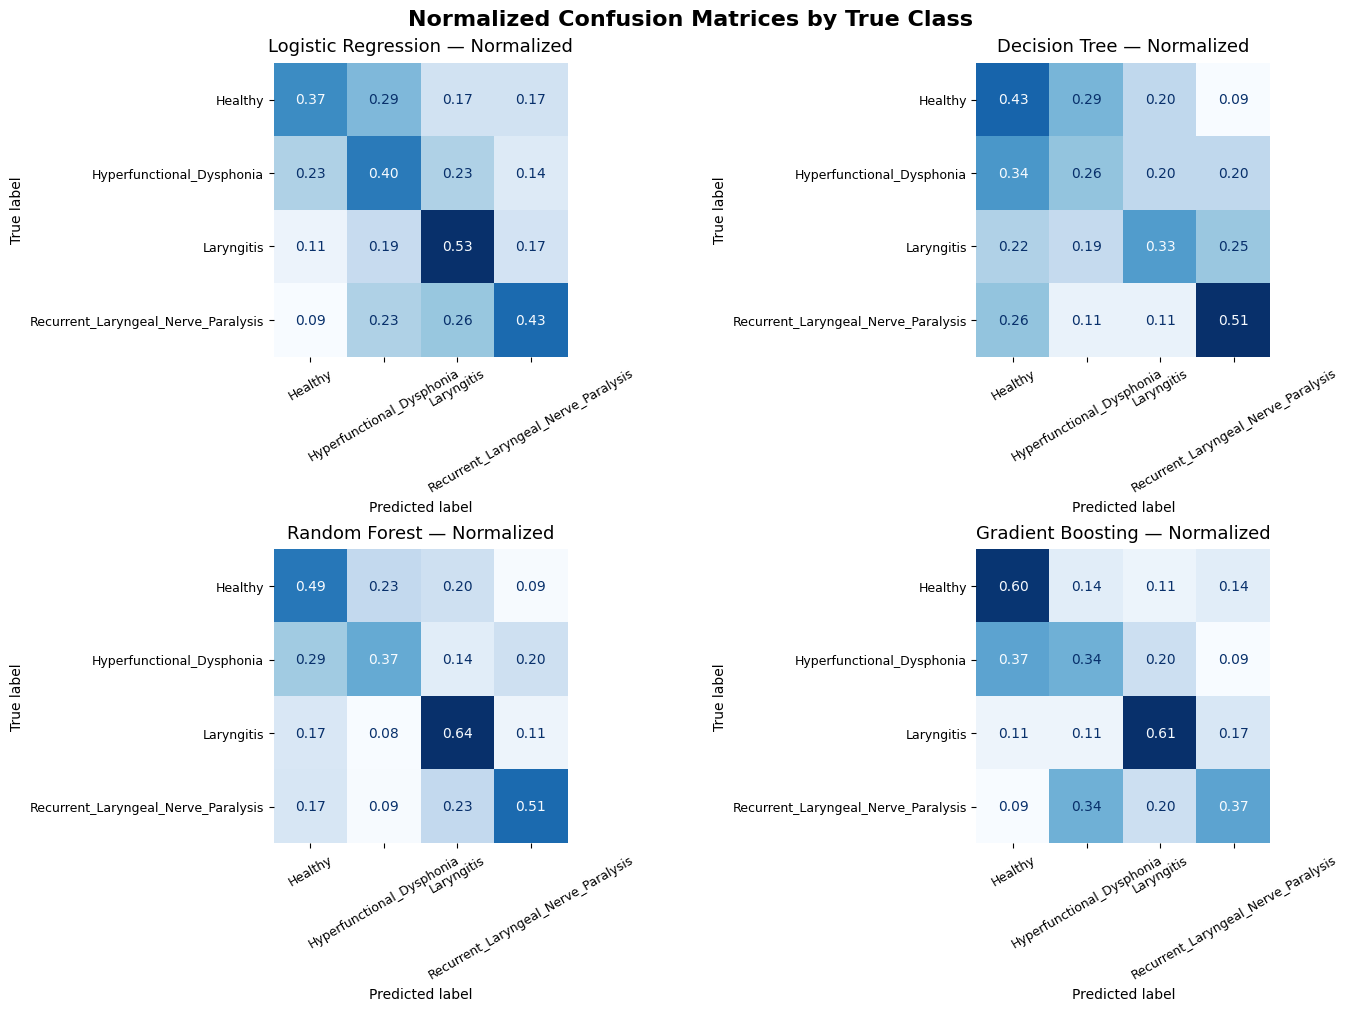

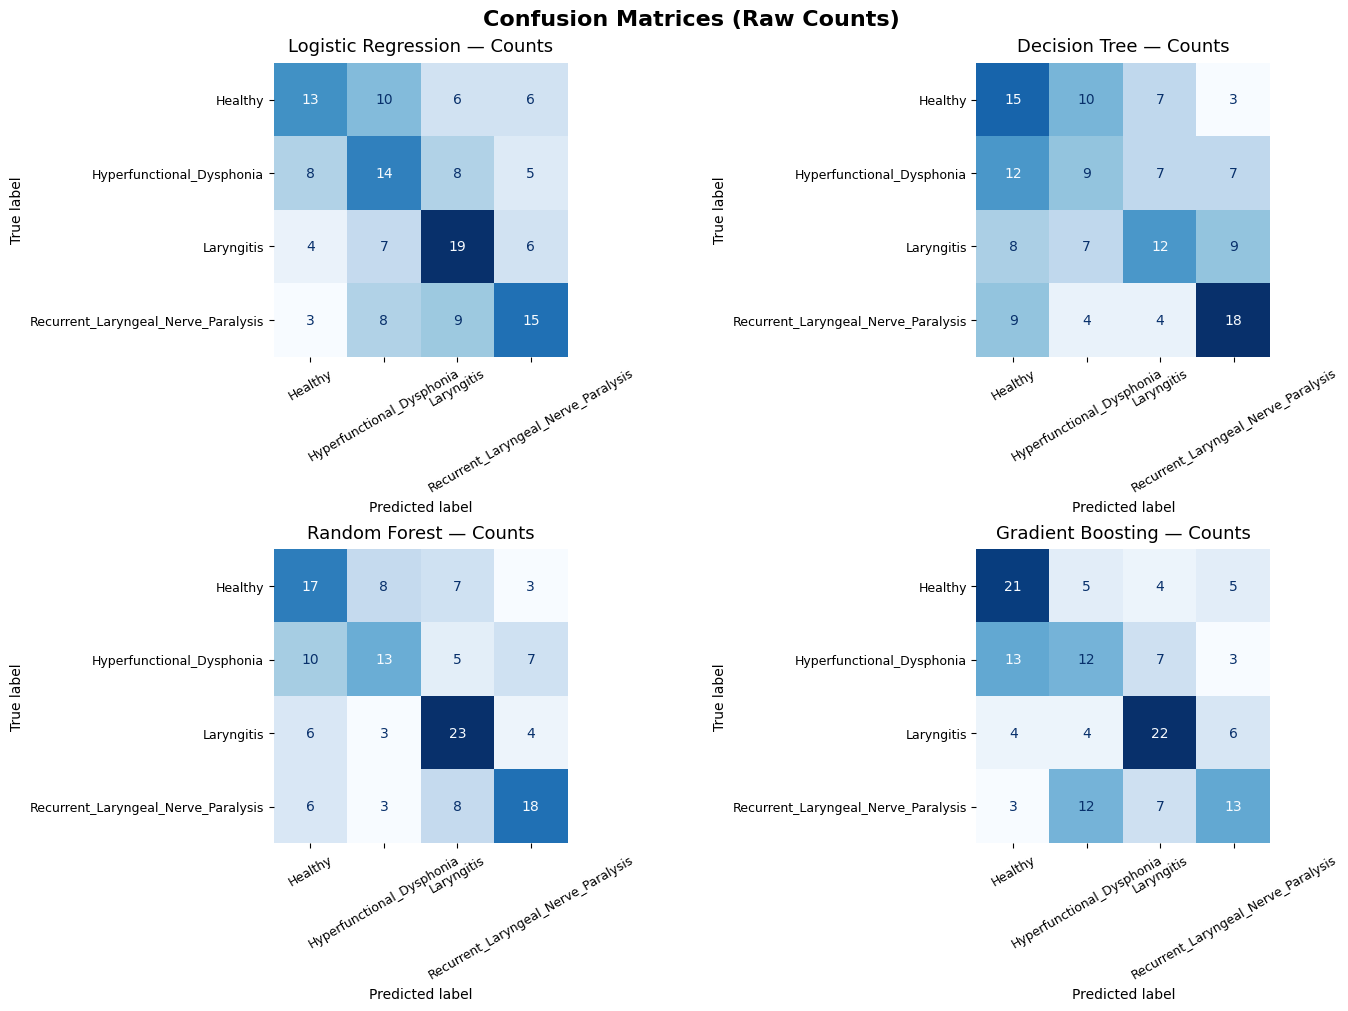

MODEL PERFORMANCE SUMMARY
              model  accuracy  balanced_accuracy  macro_F1
      Random Forest  0.503546           0.502579  0.499602
  Gradient Boosting  0.482270           0.481349  0.475969
Logistic Regression  0.432624           0.431944  0.431504
      Decision Tree  0.382979           0.383333  0.380077


In [47]:
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

NSP_PATH   = str(OUTPUT_ROOT / "Speech_pathologies_dataset_NSP_features.csv")
EGG_PATH   = str(OUTPUT_ROOT / "Speech_pathologies_dataset_EGG_features_pat.csv")
MODEL_PATH = str(OUTPUT_ROOT / "trained_model_EGG_NSP.pkl")


#Load & fuse (patient-level)
df_nsp = pd.read_csv(NSP_PATH)
df_egg = pd.read_csv(EGG_PATH)

for d in (df_nsp, df_egg):
    d["patient_id"] = d["patient_id"].astype(str)
    d["class"] = d["class"].astype(str)

#Keep only patients present in BOTH modalities
df = pd.merge(
    df_nsp, df_egg,
    on=["patient_id", "class"],
    suffixes=("_nsp", "_egg"),
    how="inner"
)

META = ["class", "patient_id"]
X_all = df.drop(columns=META, errors="ignore").select_dtypes(include=[np.number])
y_all_str = df["class"].astype(str)

#Encode classes 0..n-1
le = LabelEncoder()
y_all = le.fit_transform(y_all_str)

#Simple numeric NaN handling
X_all = X_all.fillna(X_all.mean())

#Patient-wise split and stratification
def patient_split(frame, test_size=0.25, random_state=42):
    rng = np.random.RandomState(random_state)
    train_pats, test_pats = set(), set()
    for _, g in frame.groupby("class"):
        pats = g["patient_id"].astype(str).unique().tolist()
        rng.shuffle(pats)
        n_test = max(1, int(round(len(pats) * test_size)))
        test_pats |= set(pats[:n_test])
        train_pats |= set(pats[n_test:])
    train_idx = frame.index[frame["patient_id"].astype(str).isin(train_pats)]
    test_idx  = frame.index[frame["patient_id"].astype(str).isin(test_pats)]
    return train_idx, test_idx

train_idx, test_idx = patient_split(df, test_size=0.25, random_state=42)

X_train, X_test = X_all.loc[train_idx], X_all.loc[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]

print(f"Train patients: {df.loc[train_idx, 'patient_id'].nunique()} | Test patients: {df.loc[test_idx, 'patient_id'].nunique()}")
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")


def make_pipeline(clf, k=None, scale=False):
    steps = [("imputer", SimpleImputer(strategy="mean"))]
    if k is not None:
        steps.append(("select", SelectKBest(f_classif, k=min(int(k), X_train.shape[1]))))
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)

models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=3000, solver="saga", multi_class="multinomial", random_state=42),
        k=60, scale=True
    ),
    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(random_state=42), k=30
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1),
        k=120
    ),
    "Gradient Boosting": make_pipeline(
        GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3,validation_fraction=0.1, n_iter_no_change=10, random_state=42),
        k=120
    ),
}


fitted_models = {}
y_preds = {}
perfs = []

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    y_pred = pipe.predict(X_test)
    y_preds[name] = y_pred

    acc  = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    mf1  = f1_score(y_test, y_pred, average="macro")
    perfs.append((name, acc, bacc, mf1))
    print(f"{name:<20} | Test Accuracy: {acc:.3f}")


labels_true = np.arange(len(le.classes_))
labels_display = list(le.classes_)

def plot_confusion(ax, y_true, y_pred, labels_true, labels_display, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels_true, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_display)
    fmt = ".2f" if normalize else "d"
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=fmt)
    ax.set_title(title, fontsize=13, pad=8)
    ax.tick_params(axis="x", labelrotation=30, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

#Normalized
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Normalized", normalize="true")
fig.suptitle("Normalized Confusion Matrices by True Class", fontsize=16, fontweight="bold")
plt.show()

#Raw counts
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, (name, y_pred) in zip(axes.ravel(), y_preds.items()):
    plot_confusion(ax, y_test, y_pred, labels_true, labels_display, f"{name} — Counts", normalize=None)
fig.suptitle("Confusion Matrices (Raw Counts)", fontsize=16, fontweight="bold")
plt.show()

summary = pd.DataFrame(perfs, columns=["model","accuracy","balanced_accuracy","macro_F1"])

print("MODEL PERFORMANCE SUMMARY")
print(summary.sort_values("accuracy", ascending=False).to_string(index=False))

## Optional local microphone demonstration

This cell loads the locally trained NSP model and uses the microphone; it is **disabled by default** (`RUN_LIVE_DEMO = False`). The historical output below is from the original experiment, not a reproducible clinical validation. A trained `.pkl` model and access to a microphone are required.


In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)


NSP_PATH   = str(OUTPUT_ROOT / "Speech_pathologies_dataset_NSP_features.csv")
MODEL_PATH = str(OUTPUT_ROOT / "trained_model_NSP.pkl")

DURATION = 5        #seconds 
FS = 44100          #Hz
N_REPEATS = 3       #record 3 short takes and average features
UNCERTAIN_THRESHOLD = 0.60  


df_nsp = pd.read_csv(NSP_PATH)
META = {"class","patient_id","filename","filepath","vowel","condition","sample_rate","duration_sec"}
EXPECTED_COLS = [c for c in df_nsp.columns if c not in META and df_nsp[c].dtype != "object"]


def pre_emphasis(y, coeff=0.97):
    if y.size < 2: return y
    return np.append(y[0], y[1:] - coeff * y[:-1])

def bandpass_soft(y, sr, fmin=70, fmax=4000):
    #librosa's filters (simple & fast)
    y = librosa.effects.preemphasis(y, coef=0.0)  #keep neutral; we do our own above
    #Use FFT masking for a light band-limit without changing feature keys
    Y = np.fft.rfft(y)
    freqs = np.fft.rfftfreq(len(y), 1/sr)
    mask = (freqs >= fmin) & (freqs <= fmax)
    Y *= mask
    return np.fft.irfft(Y, n=len(y))

def trim_and_normalize(y, sr):
    y, _ = librosa.effects.trim(y, top_db=30)  #this removes leading/trailing silence
    y = y.astype(np.float32)
    if y.size == 0:
        return y
    y = y - np.mean(y)
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak
    return y

#Feature extraction 
N_MFCC = 13

def robust_f0_feats(y, sr):
    f0_mean = np.nan
    f0_std  = np.nan
    jitter  = 0.0
    try:
        f0, _, _ = librosa.pyin(y, fmin=50, fmax=400, sr=sr)
    except Exception:
        f0 = None
    if f0 is None or np.all(np.isnan(f0)):
        try:
            f0 = librosa.yin(y, fmin=50, fmax=400, sr=sr)
        except Exception:
            f0 = None

    if f0 is not None and np.any(~np.isnan(f0)):
        f0v = f0[~np.isnan(f0)]
        if f0v.size > 0:
            f0_mean = float(np.mean(f0v))
            f0_std  = float(np.std(f0v))
            jitter  = float(np.mean(np.abs(np.diff(f0v))) / (np.mean(f0v) + 1e-8)) if f0v.size > 1 else 0.0

    #If still NaN the codeuses zeros so the imputer doesn’t complain
    if not np.isfinite(f0_mean): f0_mean = 0.0
    if not np.isfinite(f0_std):  f0_std  = 0.0
    if not np.isfinite(jitter):  jitter  = 0.0
    return f0_mean, f0_std, jitter

def extract_nsp_features(y: np.ndarray, sr: int) -> dict:
    #Clean up to stabilize live features
    y = trim_and_normalize(y, sr)
    y = pre_emphasis(y, 0.97)
    y = bandpass_soft(y, sr, 70, 4000)

    feats = {}

    #time-domain
    feats["rms_mean"] = float(np.mean(librosa.feature.rms(y=y)))
    feats["rms_std"]  = float(np.std(librosa.feature.rms(y=y)))
    zcr = librosa.feature.zero_crossing_rate(y=y)[0]
    feats["zcr_mean"] = float(np.mean(zcr))
    feats["zcr_std"]  = float(np.std(zcr))

    #pitch & stability (robust)
    f0_mean, f0_std, jitter = robust_f0_feats(y, sr)
    feats["f0_mean"] = f0_mean
    feats["f0_std"]  = f0_std
    feats["jitter"]  = jitter

    #frequency-domain
    sc = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    sb = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    sf = librosa.feature.spectral_flatness(y=y)[0]
    sro = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)[0]
    feats["spec_centroid_mean"] = float(np.mean(sc));  feats["spec_centroid_std"] = float(np.std(sc))
    feats["spec_bw_mean"]       = float(np.mean(sb));  feats["spec_bw_std"]       = float(np.std(sb))
    feats["spec_flat_mean"]     = float(np.mean(sf));  feats["spec_flat_std"]     = float(np.std(sf))
    feats["spec_roll_mean"]     = float(np.mean(sro)); feats["spec_roll_std"]     = float(np.std(sro))

    #MFCCs (means only, to match your CSV naming)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    for i in range(N_MFCC):
        feats[f"mfcc_{i+1}_mean"] = float(np.mean(mfcc[i]))

    #CHROMA (means)
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    for i in range(chroma.shape[0]):
        feats[f"chroma_{i+1}_mean"] = float(np.mean(chroma[i]))

    #SPECTRAL CONTRAST (means)
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    for i in range(contrast.shape[0]):
        feats[f"contrast_{i+1}_mean"] = float(np.mean(contrast[i]))

    return feats


#Record audio—  average of the 3 takes
def record_one(seconds=DURATION, fs=FS):
    print("Recording...")
    audio = sd.rec(int(seconds * fs), samplerate=fs, channels=1, dtype="float32")
    sd.wait()
    print("  Done.")
    y = audio.flatten()
    return y, fs

def record_and_average_features(n_repeats=N_REPEATS, seconds=DURATION, fs=FS):
    all_feats = []
    print("\nPlease speak a steady vowel (ex:'aaaaa') for ~5 seconds each time.")
    sd.sleep(800)
    for r in range(n_repeats):
        print(f"\nTake {r+1} of {n_repeats} starts in 1 second…")
        sd.sleep(1000)
        y, sr = record_one(seconds, fs)
        feats = extract_nsp_features(y, sr)
        all_feats.append(feats)
    # average dictionaries
    keys = all_feats[0].keys()
    avg = {k: float(np.mean([f[k] for f in all_feats])) for k in keys}
    return avg

CLASS_MAP = {
    0: "Healthy",
    1: "Hyperfunctional Dysphonia",
    2: "Laryngitis",
    3: "Recurrent Laryngeal Nerve Paralysis",
}
STRING_CLASS_MAP = {v.replace(" ", "_"): v for v in CLASS_MAP.values()}

def pretty_label(c):
    try:
        return CLASS_MAP.get(int(c), str(c))
    except (ValueError, TypeError):
        return STRING_CLASS_MAP.get(str(c), str(c).replace("_", " "))


#Prediction
def main():
    if not Path(MODEL_PATH).exists():
        raise FileNotFoundError(f"MODEL_PATH not found: {MODEL_PATH}")
    pipe = joblib.load(MODEL_PATH)

    feats = record_and_average_features()
    X = pd.DataFrame([feats])

    #align with expected columns (same order as training CSV)
    for c in [c for c in EXPECTED_COLS if c not in X.columns]:
        X[c] = 0.0
    X = X.reindex(columns=EXPECTED_COLS, fill_value=0.0).astype(float)

    #Predict
    classes = list(getattr(pipe, "classes_", []))
    y_pred = pipe.predict(X)[0]
    proba = pipe.predict_proba(X)[0] if hasattr(pipe, "predict_proba") else np.zeros(len(classes))
    max_prob = float(np.max(proba)) if proba.size else 0.0

    pred_label_raw = classes[int(y_pred)] if classes else y_pred
    pred_label = pretty_label(pred_label_raw)

    order = np.argsort(proba)[::-1] if proba.size else []
    print("\n            RESULT           ")
    print(f"Predicted voice class (averaged across {N_REPEATS} takes): {pred_label}")
    print(f"Confidence: {max_prob*100:.1f}%")
    if proba.size:
        print("\nClass probabilities:")
        for i in order:
            print(f"   {pretty_label(classes[i]):<35}: {proba[i]*100:.1f}%")


    if max_prob < UNCERTAIN_THRESHOLD and pred_label != "Healthy":
        print("Low confidence on a pathologic label. Consider re-recording in a quieter room and keep the vowel steady.")

# Set to True only when you intentionally want a local microphone demonstration.
RUN_LIVE_DEMO = False
if RUN_LIVE_DEMO:
    main()



Please speak a steady vowel (ex:'aaaaa') for ~5 seconds each time.

Take 1 of 3 starts in 1 second…
Recording...
  Done.

Take 2 of 3 starts in 1 second…
Recording...
  Done.

Take 3 of 3 starts in 1 second…
Recording...
  Done.

            RESULT           
Predicted diagnosis (averaged across 3 takes): Healthy
Confidence: 100.0%

Class probabilities:
   Healthy                            : 100.0%
   Laryngitis                         : 0.0%
   Hyperfunctional Dysphonia          : 0.0%
   Recurrent Laryngeal Nerve Paralysis: 0.0%
